# Classical Data Augmentation

We apply classical **Harmoniq**-style data augmentation to noisy complex-valued
signals and measure whether it improves standard classifiers. Harmoniq augments a
dataset with a *localized Weyl–Heisenberg (time–frequency shift) channel*; the
original paper studies its denoising effect on PCA. Here we ask the classical,
supervised analogue: does the same augmentation recover classification accuracy that
additive noise destroys, and does the effect strengthen with system size $n$ (where
the signal dimension is $d = 2^{n}$)?

The data and the augmentation operators are Harmoniq's own, imported directly from the
cloned `harmoniq/` package (`gaussnk`, `rotmod`, `apply_WH`, `gaussian_window_weights`).
We focus on a small **MLP** and a tiny **1D-CNN**, and reproduce the paper's presentation
style: results for different system sizes drawn as a gradient of a single colour.
Every complex signal is fed to the networks as two real channels, `[real, imag]`.

In [1]:
import json
import copy
import hashlib
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable

import sys
sys.path.insert(0, "harmoniq")
from generate_data import gaussnk, rotmod
from gates import apply_WH
from utils import gaussian_window_weights

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
FIGDIR = Path("figures")
for p in (DATA_DIR, RESULTS_DIR, FIGDIR):
    p.mkdir(exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

device: cuda | NVIDIA GeForce RTX 5080


## Dataset

Both classes are generated with Harmoniq's own functions (`gaussnk`, `rotmod` imported
from `harmoniq/generate_data.py`): a normalized Gaussian window is spread into 12
time–frequency-shifted copies arranged in three clusters. Harmoniq is single-class; the
two classes here differ only in the placement of two clusters — class 0 uses the shipped
`DUM_clean` configuration, class 1 a shifted variant. Each signal is an independent random
combination, so we draw a large fixed number `PER_CLASS` per class (decoupling the sample
budget from $d$, so large $m$ is reachable at every $n$). Datasets are cached as `.npy`.

In [2]:
PER_CLASS = 4096


def cluster_coords(n, which):
    d = 2 ** n
    base = np.array([[1, 1], [1, 2], [2, 2], [2, 1]])
    if which == 0:
        extra = [base + [d // 4, d // 4], base + [d - d // 4, d // 16]]
    else:
        extra = [base + [d // 2, d // 8], base + [d - d // 8, d // 2]]
    return np.vstack([base, *extra])


def generate_class(n, which, count, seed=42):
    d = 2 ** n
    g = gaussnk(d)
    coords = cluster_coords(n, which)
    rng = np.random.default_rng(seed)
    F = np.zeros((count, d), dtype=complex)
    for i in range(count):
        c = rng.standard_normal(12)
        c = c / np.linalg.norm(c)
        f = np.zeros(d, dtype=complex)
        for k in range(12):
            f += c[k] * rotmod(g, coords[k, 0], coords[k, 1])
        F[i] = f
    return F.astype(np.complex64)


def load_class(n, which, count=PER_CLASS):
    f = DATA_DIR / f"clean_class{which}_n{n}_N{count}.npy"
    if not f.exists():
        np.save(f, generate_class(n, which, count))
    return np.load(f)


def load_dataset(n):
    X0, X1 = load_class(n, 0), load_class(n, 1)
    return X0, np.zeros(len(X0)), X1, np.ones(len(X1))


def to_channels(Xc):
    return np.stack([Xc.real, Xc.imag], axis=1).astype(np.float32)

## The Weyl–Heisenberg augmentation

Augmentation uses Harmoniq's own operators: `apply_WH` applies a phase-space
displacement $W(x,z) = \omega^{xz} Z^z X^x$, and `gaussian_window_weights(size)` returns
the localized window $\Omega$ (an odd $\text{size}\times\text{size}$ grid centred at the
origin, Gaussian-weighted, $\sigma = r/2$), so $|\Omega| = \text{size}^2$. Following the
paper, the main experiments use the **$n$-dependent window** `window_size(n)` = $n$ (odd)
/ $n-1$ (even), i.e. $|\Omega| = n^2/(n-1)^2$; the $|\Omega|$ sweep varies it independently.
We expand **every** $(x,z)\in\Omega$ — one augmented copy per displacement, weighted by
$\lambda(x,z)$ (carried as a per-sample loss weight) — matching the weighted average in
Harmoniq's `run_algorithm`. Only the (noisy) training signals are augmented.

In [3]:
def window_size(n):
    return n if n % 2 == 1 else n - 1


def omega(size):
    if size <= 1:
        return np.array([[0, 0]]), np.array([1.0])
    w = gaussian_window_weights(size)
    offs = np.array(list(w.keys()))
    wts = np.array(list(w.values()))
    return offs, wts


def make_augmented(Xc, y, size):
    d = Xc.shape[1]
    offs, wts = omega(size)
    Xa, ya, wa = [], [], []
    for (x, z), wt in zip(offs, wts):
        Xa.append(apply_WH(d, int(x) % d, int(z) % d, Xc))
        ya.append(y)
        wa.append(np.full(len(y), wt))
    return (np.concatenate(Xa).astype(np.complex64),
            np.concatenate(ya), np.concatenate(wa))


for n in range(6, 11):
    print(f"n={n:2d}  window={window_size(n)}  ->  |Omega| = {window_size(n) ** 2}")

n= 6  window=5  ->  |Omega| = 25
n= 7  window=7  ->  |Omega| = 49
n= 8  window=7  ->  |Omega| = 49
n= 9  window=9  ->  |Omega| = 81
n=10  window=9  ->  |Omega| = 81


## Architectures

Each model consumes the two-channel real representation. The hidden widths below are
the smallest that still classify the clean task (see the parameter search further
down). The SVM uses an RBF kernel on the standardized `[real, imag]` feature vector.

In [4]:
class MLP(nn.Module):
    def __init__(self, d, hidden=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(), 
            nn.Linear(2 * d, hidden),
            nn.ReLU(), nn.Linear(hidden, 1)
        )

    def forward(self, x):
        return self.net(x)


class CNN(nn.Module):
    def __init__(self, d, ch=4, pool=4):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(2, ch, 5, padding=2), nn.ReLU(), nn.AvgPool1d(2),
            nn.Conv1d(ch, 2 * ch, 5, padding=2), nn.ReLU(),
            nn.AdaptiveAvgPool1d(pool))
        self.head = nn.Linear(2 * ch * pool, 1)

    def forward(self, x):
        return self.head(self.features(x).flatten(1))


class LSTMNet(nn.Module):
    def __init__(self, d, hidden=8, max_len=64):
        super().__init__()
        self.stride = max(1, d // max_len)
        self.lstm = nn.LSTM(2, hidden, batch_first=True, bidirectional=True)
        self.head = nn.Linear(2 * hidden, 1)

    def forward(self, x):
        x = x[:, :, ::self.stride]
        x = (x - x.mean(-1, keepdim=True)) / (x.std(-1, keepdim=True) + 1e-6)
        _, (h, _) = self.lstm(x.transpose(1, 2))
        return self.head(torch.cat([h[-2], h[-1]], dim=1))


def count_params(model):
    return sum(p.numel() for p in model.parameters())


ARCHS = {
    "MLP": {"kind": "torch", "lr": 1e-3, "build": lambda d, h=8: MLP(d, h)},
    "CNN": {"kind": "torch", "lr": 1e-3, "build": lambda d, h=4: CNN(d, h)},
    "LSTM": {"kind": "torch", "lr": 3e-3, "build": lambda d, h=8: LSTMNet(d, h)},
    "SVM": {"kind": "sklearn", "lr": None, "build": lambda d, h=None: make_pipeline(
        StandardScaler(), SVC(kernel="rbf", C=10.0, gamma="scale"))},
}

## Training and evaluation

There is no train/test split of the sampled data. Each class is partitioned once into a
large fixed **validation** pool and a large fixed **test** pool (both independent of $m$
and identical across seeds), and the $m$ training signals are drawn from the remainder.
Training length is measured in **gradient updates $T$, not epochs**, so it is consistent
across window sizes and dataset sizes: we evaluate the validation loss periodically, stop
when it has not improved for `PATIENCE_UPDATES` updates (a large, smooth val set makes this
stable even at small $m$), restore the best weights, and report **test** accuracy. Augmented
copies carry the window weight $\lambda$ as a per-sample loss weight.

In [5]:
VALID_CAP, TEST_CAP = 500, 500
MAX_UPDATES, EVAL_EVERY, PATIENCE_UPDATES, MIN_DELTA = 30000, 200, 2500, 1e-4


def make_pools(X0, X1):
    c = len(X0)
    v = min(c // 4, VALID_CAP)
    t = min(c // 4, TEST_CAP)
    Xte = np.concatenate([X0[c - t:], X1[c - t:]])
    yte = np.concatenate([np.zeros(t), np.ones(t)])
    Xva = np.concatenate([X0[c - t - v:c - t], X1[c - t - v:c - t]])
    yva = np.concatenate([np.zeros(v), np.ones(v)])
    return X0[:c - t - v], X1[:c - t - v], (Xva, yva), (Xte, yte)


def draw_train(pool0, pool1, m, seed):
    per = m // 2
    rng = np.random.default_rng(seed)
    i0 = rng.choice(len(pool0), min(per, len(pool0)), replace=False)
    i1 = rng.choice(len(pool1), min(per, len(pool1)), replace=False)
    return (np.concatenate([pool0[i0], pool1[i1]]),
            np.concatenate([np.zeros(len(i0)), np.ones(len(i1))]))


def max_m(X0):
    c = len(X0)
    return 2 * (c - min(c // 4, VALID_CAP) - min(c // 4, TEST_CAP))


def binary_accuracy(logits, y):
    return ((torch.sigmoid(logits) > 0.5).float() == y).float().mean().item()


def eval_acc(model, Xc, y):
    model.eval()
    with torch.no_grad():
        return binary_accuracy(model(_t(Xc)), _y(y))


def _t(X):
    return torch.tensor(to_channels(X), device=DEVICE)


def _y(y):
    return torch.tensor(y, dtype=torch.float32, device=DEVICE).unsqueeze(1)


def train_torch(model, Xtr, ytr, Xva, yva, Xte, yte, wtr=None,
                max_updates=MAX_UPDATES, eval_every=EVAL_EVERY,
                patience=PATIENCE_UPDATES, min_delta=MIN_DELTA,
                batch_size=64, lr=1e-3, seed=0, history=False):
    torch.manual_seed(seed)
    model = model.to(DEVICE)
    if wtr is None:
        wtr = np.ones(len(ytr))
    Xt, yt = _t(Xtr), _y(ytr)
    wt = torch.tensor(wtr, dtype=torch.float32, device=DEVICE).unsqueeze(1)
    Xv, yv = _t(Xva), _y(yva)
    loader = DataLoader(TensorDataset(Xt, yt, wt), batch_size=batch_size, shuffle=True)
    eval_stride = max(1, min(eval_every, len(loader)))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.BCEWithLogitsLoss(reduction="none")
    best_state, best_loss, best_update = copy.deepcopy(model.state_dict()), np.inf, 0
    hist = {"update": [], "train_loss": [], "val_loss": [], "val_acc": [], "val_auc": []}
    yv_np = yva
    updates, run_loss, run_n, stop = 0, 0.0, 0, False
    while updates < max_updates and not stop:
        model.train()
        for xb, yb, wb in loader:
            opt.zero_grad()
            loss = (crit(model(xb), yb) * wb).sum() / wb.sum()
            loss.backward()
            opt.step()
            updates += 1
            run_loss += loss.item()
            run_n += 1
            if updates % eval_stride == 0:
                model.eval()
                with torch.no_grad():
                    logits = model(Xv)
                    vl = crit(logits, yv).mean().item()
                    va = binary_accuracy(logits, yv)
                    proba = torch.sigmoid(logits).cpu().numpy().ravel()
                model.train()
                hist["update"].append(updates)
                hist["train_loss"].append(run_loss / run_n)
                hist["val_loss"].append(vl)
                hist["val_acc"].append(va)
                hist["val_auc"].append(roc_auc_score(yv_np, proba))
                run_loss, run_n = 0.0, 0
                if vl < best_loss - min_delta:
                    best_loss, best_update = vl, updates
                    best_state = copy.deepcopy(model.state_dict())
                elif updates - best_update >= patience:
                    stop = True
                    break
            if updates >= max_updates:
                break
    model.load_state_dict(best_state)
    if history:
        return model, hist
    model.eval()
    with torch.no_grad():
        return binary_accuracy(model(_t(Xte)), _y(yte))


def train_sklearn(model, Xtr, ytr, Xte, yte, cap=4000, seed=0):
    rng = np.random.default_rng(seed)
    if len(Xtr) > cap:
        idx = rng.choice(len(Xtr), cap, replace=False)
        Xtr, ytr = Xtr[idx], ytr[idx]
    ftr = np.concatenate([Xtr.real, Xtr.imag], axis=1)
    fte = np.concatenate([Xte.real, Xte.imag], axis=1)
    model.fit(ftr, ytr)
    return float(model.score(fte, yte))


def fit_eval(arch, d, Xtr, ytr, wtr, Xva, yva, Xte, yte, seed=0):
    cfg = ARCHS[arch]
    if cfg["kind"] == "torch":
        return train_torch(cfg["build"](d), Xtr, ytr, Xva, yva, Xte, yte,
                           wtr=wtr, lr=cfg["lr"], seed=seed)
    return train_sklearn(cfg["build"](d), Xtr, ytr, Xte, yte, seed=seed)


def add_noise(X, sigma, rng):
    return (X + rng.normal(0, sigma, X.shape)
            + 1j * rng.normal(0, sigma, X.shape)).astype(np.complex64)


def run_point(X0, X1, arch, sigma, m, seed, size):
    d = X0.shape[1]
    pool0, pool1, (Xva, yva), (Xte, yte) = make_pools(X0, X1)
    Xtr, ytr = draw_train(pool0, pool1, m, seed)
    trng = np.random.default_rng(1000 + seed)
    erng = np.random.default_rng(999)
    Xtr_n = add_noise(Xtr, sigma, trng)
    Xva_n, Xte_n = add_noise(Xva, sigma, erng), add_noise(Xte, sigma, erng)
    res = {"clean": fit_eval(arch, d, Xtr, ytr, None, Xva, yva, Xte, yte, seed),
           "noisy": fit_eval(arch, d, Xtr_n, ytr, None, Xva_n, yva, Xte_n, yte, seed)}
    Xa, ya, wa = make_augmented(Xtr_n, ytr, size)
    res["augmented"] = fit_eval(arch, d, Xa, ya, wa, Xva_n, yva, Xte_n, yte, seed)
    return res

## Cached sweeps

Each sweep is written to `results/` keyed by its configuration, so re-running the
notebook reloads cached numbers instead of recomputing. Set `force=True` to recompute.

In [6]:
import time

CONDS = ("clean", "noisy", "augmented")


def cached(key, fn, force=False):
    tag = hashlib.md5(json.dumps(key, sort_keys=True).encode()).hexdigest()[:16]
    f = RESULTS_DIR / f"{tag}.pkl"
    if f.exists() and not force:
        return pickle.load(open(f, "rb"))
    val = fn()
    pickle.dump(val, open(f, "wb"))
    return val


def _log(tag, done, total, t0, extra=""):
    el = time.time() - t0
    eta = el / done * (total - done) if done else 0
    print(f"[{tag}] {done:3d}/{total} ({100 * done / total:3.0f}%) "
          f"elapsed {el:5.0f}s eta {eta:5.0f}s  {extra}", flush=True)


def sweep_m(arch, n_values, m_values, sigma, seeds, window, force=False):
    key = dict(kind="m", arch=arch, n=list(n_values), m=list(m_values),
               sigma=sigma, window=window, seeds=list(seeds))

    def run():
        out = {c: {} for c in CONDS}
        t0, done = time.time(), 0
        jobs = 0
        for n in n_values:
            X0, _, X1, _ = load_dataset(n)
            jobs += sum(m <= max_m(X0) for m in m_values)
        for n in n_values:
            X0, _, X1, _ = load_dataset(n)
            size = window_size(n) if window is None else window
            for c in CONDS:
                out[c][n] = {}
            for m in m_values:
                if m > max_m(X0):
                    continue
                accs = {c: [] for c in CONDS}
                for s in seeds:
                    r = run_point(X0, X1, arch, sigma, m, s, size)
                    for c in CONDS:
                        accs[c].append(r[c])
                for c in CONDS:
                    out[c][n][m] = np.array(accs[c])
                done += 1
                _log(f"sweep_m {arch}", done, jobs, t0,
                     f"n={n} m={m} aug={out['augmented'][n][m].mean():.3f}")
        return out
    return cached(key, run, force)


def sweep_sigma(arch, n_values, sigma_values, m, seeds, window, force=False):
    key = dict(kind="sigma", arch=arch, n=list(n_values),
               sigma=list(sigma_values), m=m, window=window, seeds=list(seeds))

    def run():
        out = {c: {} for c in CONDS}
        total = len(n_values) * len(sigma_values)
        t0, done = time.time(), 0
        for n in n_values:
            X0, _, X1, _ = load_dataset(n)
            size = window_size(n) if window is None else window
            for c in CONDS:
                out[c][n] = {}
            for sig in sigma_values:
                accs = {c: [] for c in CONDS}
                for s in seeds:
                    r = run_point(X0, X1, arch, sig, m, s, size)
                    for c in CONDS:
                        accs[c].append(r[c])
                for c in CONDS:
                    out[c][n][sig] = np.array(accs[c])
                done += 1
                _log(f"sweep_sigma {arch}", done, total, t0, f"n={n} sigma={sig}")
        return out
    return cached(key, run, force)


def sweep_omega(arch, n_values, sizes, m, sigma, seeds, force=False):
    key = dict(kind="omega", arch=arch, n=list(n_values), sizes=list(sizes),
               m=m, sigma=sigma, seeds=list(seeds))

    def run():
        out = {c: {} for c in CONDS}
        total = len(n_values) * len(sizes)
        t0, done = time.time(), 0
        for n in n_values:
            X0, _, X1, _ = load_dataset(n)
            for c in CONDS:
                out[c][n] = {}
            for size in sizes:
                accs = {c: [] for c in CONDS}
                for s in seeds:
                    r = run_point(X0, X1, arch, sigma, m, s, size)
                    for c in CONDS:
                        accs[c].append(r[c])
                for c in CONDS:
                    out[c][n][size ** 2] = np.array(accs[c])
                done += 1
                _log(f"sweep_omega {arch}", done, total, t0, f"n={n} |Omega|={size**2}")
        return out
    return cached(key, run, force)

In [7]:
def sweep_sigma_adaptive(arch, n_values, sigma_values, candidate_sizes, m, seeds, force=False):
    key = dict(kind="sigma_adapt", arch=arch, n=list(n_values), sigma=list(sigma_values),
               cands=list(candidate_sizes), m=m, seeds=list(seeds))

    def run():
        out = {"noisy": {}, "augmented": {}, "chosen": {}}
        total = len(n_values) * len(sigma_values)
        t0, done = time.time(), 0
        for n in n_values:
            X0, _, X1, _ = load_dataset(n)
            d = X0.shape[1]
            pool0, pool1, (Xva, yva), (Xte, yte) = make_pools(X0, X1)
            for k in out:
                out[k][n] = {}
            for sig in sigma_values:
                noisy, aug, chosen = [], [], []
                for seed in seeds:
                    Xtr, ytr = draw_train(pool0, pool1, m, seed)
                    trng, erng = np.random.default_rng(1000 + seed), np.random.default_rng(999)
                    Xtr_n = add_noise(Xtr, sig, trng)
                    Xva_n, Xte_n = add_noise(Xva, sig, erng), add_noise(Xte, sig, erng)
                    noisy.append(fit_eval(arch, d, Xtr_n, ytr, None, Xva_n, yva, Xte_n, yte, seed))
                    best_val, best_test, best_size = -1.0, 0.0, candidate_sizes[0]
                    for s in candidate_sizes:
                        Xa, ya, wa = make_augmented(Xtr_n, ytr, s)
                        model, _ = train_torch(ARCHS[arch]["build"](d), Xa, ya, Xva_n, yva,
                                               Xte_n, yte, wtr=wa, lr=ARCHS[arch]["lr"],
                                               seed=seed, history=True)
                        va = eval_acc(model, Xva_n, yva)
                        if va > best_val:
                            best_val, best_test, best_size = va, eval_acc(model, Xte_n, yte), s
                    aug.append(best_test)
                    chosen.append(best_size ** 2)
                out["noisy"][n][sig] = np.array(noisy)
                out["augmented"][n][sig] = np.array(aug)
                out["chosen"][n][sig] = np.array(chosen)
                done += 1
                _log(f"sweep_sigma_adapt {arch}", done, total, t0,
                     f"n={n} sigma={sig} |Omega|~{int(np.median(chosen))}")
        return out
    return cached(key, run, force)

## Run the sweeps

The main experiments use the paper's $n$-dependent window (`AUG_WINDOW=None` →
$|\Omega|=n^2/(n-1)^2$); the whole window is used at every point (no augmentation-count
knob), and the $|\Omega|$ sweep varies the window separately. Every point averages over
`SEEDS` and reports an SEM band. The MLP sample-size sweep spans all $n$; the CNN is only
needed at $n=8$ (architecture comparison), so it is computed there only. The noise and
window sweeps use the MLP. Each point prints progress with an ETA; results are cached.

In [8]:
N_VALUES = [6, 7, 8, 9, 10]
SEEDS = list(range(10))
AUG_WINDOW = None  # None => paper's n-dependent window: |Omega| = n^2 (odd n) / (n-1)^2 (even n)
M_VALUES = [16, 32, 64, 128, 256, 512, 1024, 2048, 4096]
SIGMA_VALUES = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.75, 1.0, 1.5]
OMEGA_SIZES = [1, 3, 5, 7, 9]
ARCHS_MAIN = ["MLP", "CNN"]
BEST = "MLP"

res_m = {"MLP": sweep_m("MLP", N_VALUES, M_VALUES, 0.1, SEEDS, AUG_WINDOW),
         "CNN": sweep_m("CNN", [8], M_VALUES, 0.1, SEEDS, AUG_WINDOW)}
res_sigma = sweep_sigma(BEST, N_VALUES, SIGMA_VALUES, 128, SEEDS, AUG_WINDOW)
res_omega = sweep_omega(BEST, N_VALUES, OMEGA_SIZES, 128, 0.1, SEEDS)
print("sweeps ready")

sweeps ready


## Plot styling

System size $n$ is encoded as a single-hue gradient; the clean / noisy / augmented
conditions get fixed colours, markers and line styles. Shaded bands are the **standard
error of the mean** across seeds ($\text{std}/\sqrt{n_\text{seeds}}$), so they tighten
as `SEEDS` grows.

In [9]:
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
})
NRAMP = LinearSegmentedColormap.from_list(
    "nramp", ["#a5c8ff", "#4a86e8", "#1b4fa0", "#0a2452"])
COND_STYLE = {
    "clean": dict(color="#868e96", marker="x", ls="--", label="Clean"),
    "noisy": dict(color="#e8590c", marker="o", ls="-", label="Noisy"),
    "augmented": dict(color="#2f9e44", marker="s", ls="-", label="Augmented"),
}
ARCH_COLOR = {"MLP": "#1971c2", "CNN": "#e8590c", "LSTM": "#9c36b5", "SVM": "#2b8a3e"}
ARCH_MARKER = {"MLP": "o", "CNN": "s", "LSTM": "^", "SVM": "D"}


def ncolor(n, n_values):
    lo, hi = min(n_values), max(n_values)
    return NRAMP(0.15 + 0.85 * (n - lo) / max(1, hi - lo))


def add_n_colorbar(fig, ax, n_values, label="System size $n$"):
    cb = fig.colorbar(ScalarMappable(Normalize(min(n_values), max(n_values)), NRAMP),
                      ax=ax, pad=0.02)
    cb.set_label(label)
    cb.set_ticks(list(n_values))


def ms(dct):
    xs = sorted(dct.keys())
    mean = np.array([dct[x].mean() for x in xs])
    sem = np.array([dct[x].std() / np.sqrt(len(dct[x])) for x in xs])
    return np.array(xs), mean, sem


def nreps(d):
    v = next(iter(d.values()))
    while isinstance(v, dict):
        v = next(iter(v.values()))
    return len(v)


def save(fig, name):
    fig.savefig(FIGDIR / f"{name}.png", bbox_inches="tight")

## Development: training curves

A diagnostic for choosing training length: for a range of sample sizes we train once per
condition (clean / noisy / augmented) and plot **validation loss, accuracy and AUC** against
gradient updates $T$. Because early stopping watches the large val set, the curves are smooth
even at small `m`. AUC (rank-based, threshold-free) is a more sensitive read than accuracy,
especially where accuracy is stuck near chance. These are single runs (one seed).

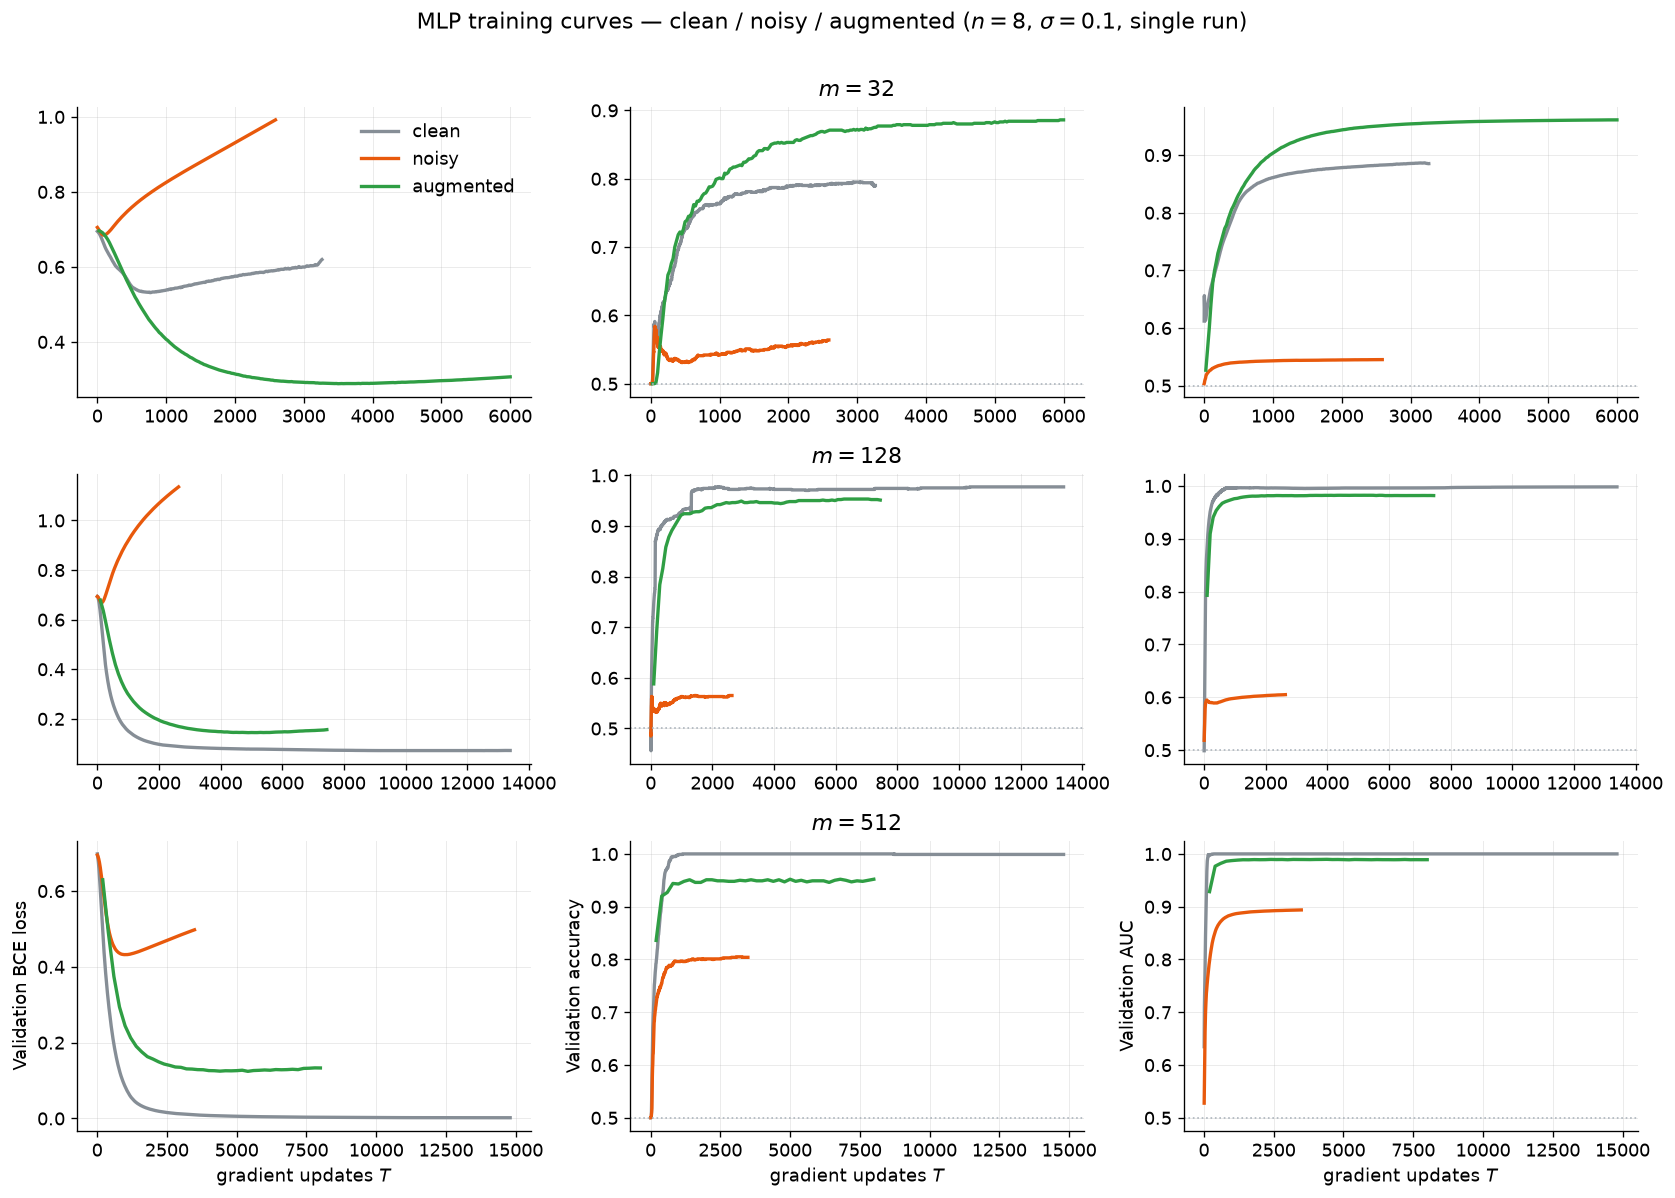

In [10]:
def _train_hist(arch, d, cond, Xtr, ytr, Xtr_n, Xva, Xva_n, yva, n, seed):
    if cond == "clean":
        Xt, yt, wa, Xv = Xtr, ytr, None, Xva
    elif cond == "noisy":
        Xt, yt, wa, Xv = Xtr_n, ytr, None, Xva_n
    else:
        Xt, yt, wa = make_augmented(Xtr_n, ytr, window_size(n))
        Xv = Xva_n
    _, hist = train_torch(ARCHS[arch]["build"](d), Xt, yt, Xv, yva, Xv, yva,
                          wtr=wa, lr=ARCHS[arch]["lr"], seed=seed, history=True)
    return hist


def plot_loss_curves(n=8, m_values=(32, 128, 512), sigma=0.1, arch="MLP",
                     conditions=("clean", "noisy", "augmented"), seed=0):
    X0, _, X1, _ = load_dataset(n)
    d = X0.shape[1]
    pool0, pool1, (Xva, yva), _ = make_pools(X0, X1)
    metrics = [("val_loss", "Validation BCE loss"),
               ("val_acc", "Validation accuracy"),
               ("val_auc", "Validation AUC")]
    R = len(m_values)
    fig, axes = plt.subplots(R, 3, figsize=(14, 3.3 * R), squeeze=False)
    for ri, m in enumerate(m_values):
        Xtr, ytr = draw_train(pool0, pool1, m, seed)
        Xtr_n = add_noise(Xtr, sigma, np.random.default_rng(1000 + seed))
        Xva_n = add_noise(Xva, sigma, np.random.default_rng(999))
        for cond in conditions:
            hist = _train_hist(arch, d, cond, Xtr, ytr, Xtr_n, Xva, Xva_n, yva, n, seed)
            u, st = hist["update"], COND_STYLE.get(cond, {"color": "#1971c2"})["color"]
            for ci, (key, _) in enumerate(metrics):
                axes[ri, ci].plot(u, hist[key], color=st, lw=2, label=cond)
        for ci, (_, label) in enumerate(metrics):
            axes[ri, ci].set_ylabel(label if ri == R - 1 else "")
            axes[ri, ci].set_title(f"$m={m}$" if ci == 1 else "")
            if ri == R - 1:
                axes[ri, ci].set_xlabel("gradient updates $T$")
        axes[ri, 1].axhline(0.5, color="#adb5bd", lw=1, ls=":")
        axes[ri, 2].axhline(0.5, color="#adb5bd", lw=1, ls=":")
    axes[0, 0].legend(loc="upper right")
    fig.suptitle(fr"{arch} training curves — clean / noisy / augmented "
                 fr"($n={n}$, $\sigma={sigma}$, single run)", y=1.005)
    fig.tight_layout()
    save(fig, "10_loss_curves")


plot_loss_curves(n=8, m_values=(32, 128, 512), sigma=0.1)
plt.show()

### Example signals
A clean signal, its noisy version, and one Weyl–Heisenberg augmentation, in the time
and power-spectral domains.

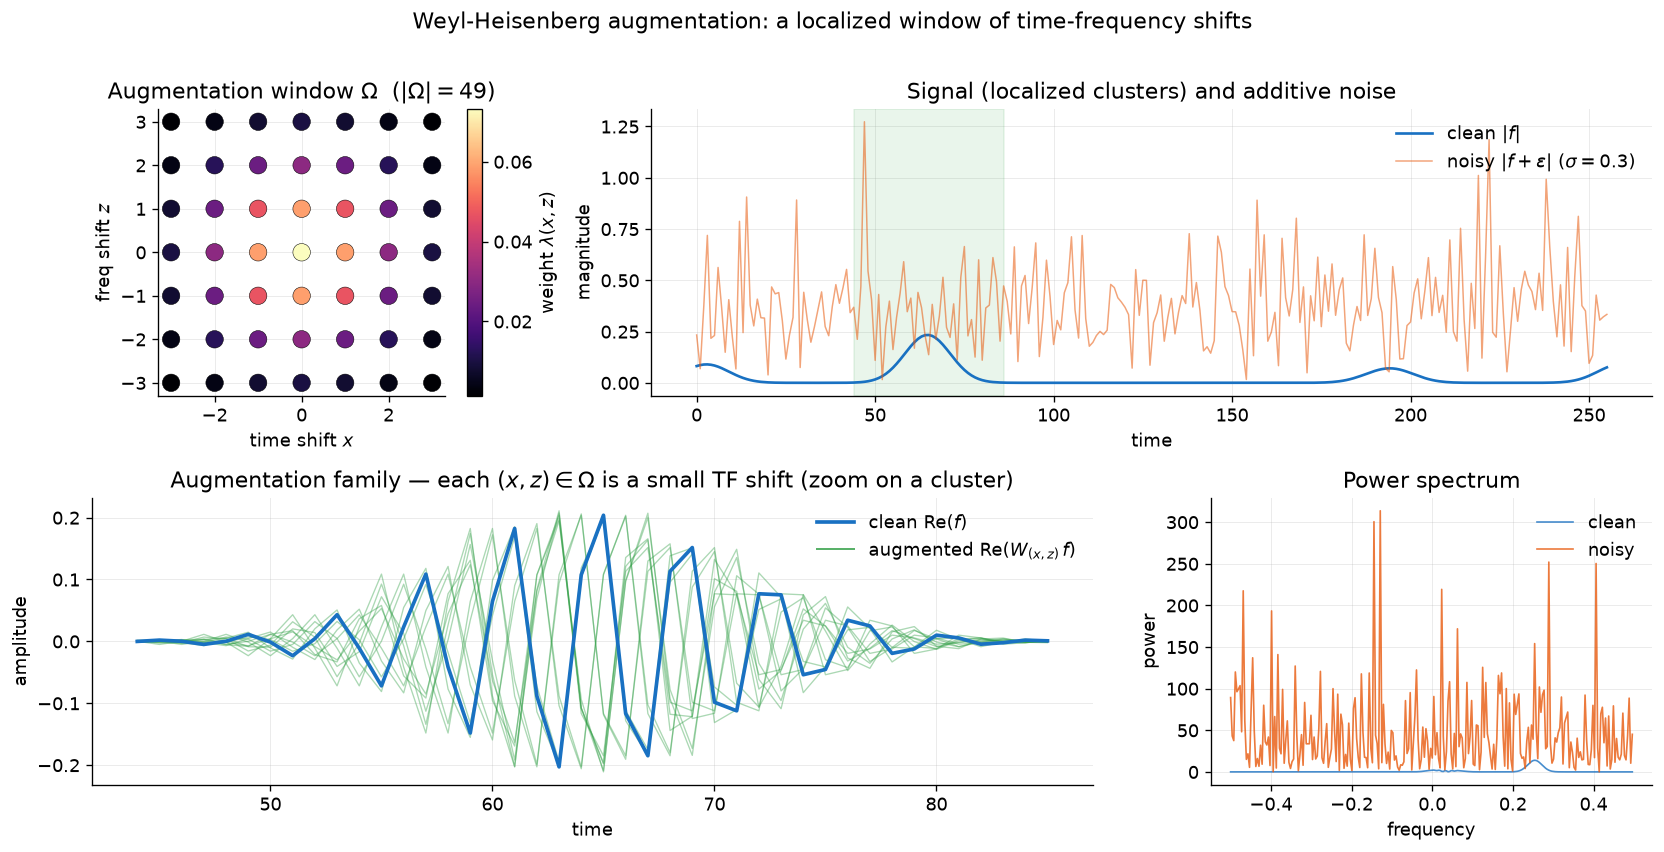

In [11]:
def plot_examples(n=8, sigma=0.3, seed=0):
    X0, _, _, _ = load_dataset(n)
    d = X0.shape[1]
    rng = np.random.default_rng(seed)
    x = X0[0]
    xn = x + rng.normal(0, sigma, x.shape) + 1j * rng.normal(0, sigma, x.shape)
    offs, wts = omega(window_size(n))
    t = np.arange(d)
    fig = plt.figure(figsize=(14, 7))
    gs = fig.add_gridspec(2, 3)

    axw = fig.add_subplot(gs[0, 0])
    sc = axw.scatter(offs[:, 0], offs[:, 1], c=wts, s=110, cmap="magma",
                     edgecolor="k", lw=0.3)
    axw.set(xlabel="time shift $x$", ylabel="freq shift $z$",
            title=fr"Augmentation window $\Omega$  ($|\Omega|={len(offs)}$)")
    axw.set_aspect("equal")
    fig.colorbar(sc, ax=axw, label=r"weight $\lambda(x,z)$")

    axc = fig.add_subplot(gs[0, 1:])
    axc.plot(t, np.abs(x), color="#1971c2", lw=1.6, label="clean $|f|$")
    axc.plot(t, np.abs(xn), color="#e8590c", lw=0.9, alpha=0.55,
             label=fr"noisy $|f+\epsilon|$ ($\sigma={sigma}$)")
    cl = int(np.argmax(np.abs(x)))
    half = max(16, d // 12)
    lo, hi = max(0, cl - half), min(d, cl + half)
    axc.axvspan(lo, hi, color="#2f9e44", alpha=0.10)
    axc.set(xlabel="time", ylabel="magnitude",
            title="Signal (localized clusters) and additive noise")
    axc.legend(loc="upper right")

    axz = fig.add_subplot(gs[1, :2])
    axz.plot(t[lo:hi], x.real[lo:hi], color="#1971c2", lw=2.2, label="clean Re$(f)$", zorder=3)
    for o in np.argsort(-wts)[:12]:
        xa = apply_WH(d, int(offs[o, 0]) % d, int(offs[o, 1]) % d, x[None, :])[0]
        axz.plot(t[lo:hi], xa.real[lo:hi], color="#2f9e44", lw=0.8, alpha=0.4)
    axz.plot([], [], color="#2f9e44", lw=1.2, alpha=0.8, label=r"augmented Re$(W_{(x,z)}\,f)$")
    axz.set(xlabel="time", ylabel="amplitude",
            title="Augmentation family — each $(x,z)\\in\\Omega$ is a small TF shift (zoom on a cluster)")
    axz.legend(loc="upper right")

    axs = fig.add_subplot(gs[1, 2])
    frq = np.fft.fftshift(np.fft.fftfreq(d))
    for s, c, lab in [(x, "#1971c2", "clean"), (xn, "#e8590c", "noisy")]:
        axs.plot(frq, np.abs(np.fft.fftshift(np.fft.fft(s))) ** 2, color=c, lw=1,
                 alpha=0.8, label=lab)
    axs.set(xlabel="frequency", ylabel="power", title="Power spectrum")
    axs.legend(loc="upper right")

    fig.suptitle("Weyl-Heisenberg augmentation: a localized window of time-frequency shifts", y=1.01)
    fig.tight_layout()
    save(fig, "00_examples")


plot_examples()
plt.show()



In [12]:
n = 8

X0, _, _, _ = load_dataset(n)
d = X0.shape[1]

# Select one clean signal.
x = X0[0]

size = window_size(n)
weights = gaussian_window_weights(size)
augmentation_indices = list(weights.keys())

n_rows = len(augmentation_indices)

fig, axes = plt.subplots(
    n_rows,
    2,
    figsize=(13, 2.5 * n_rows),
    squeeze=False,
    sharex=True,
    sharey=True,
)

for row, (x_shift, z_shift) in enumerate(augmentation_indices):
    # Apply the current Weyl–Heisenberg shift.
    xa = apply_WH(
        d,
        x_shift % d,
        z_shift % d,
        x[None, :],
    )[0]

    # Left column: always the same original signal.
    axes[row, 0].plot(
        x.real,
        color="#1971c2",
        lw=1,
        label="Re",
    )
    axes[row, 0].plot(
        x.imag,
        color="#e8590c",
        lw=1,
        alpha=0.8,
        label="Im",
    )

    axes[row, 0].set_title("Original signal")
    axes[row, 0].set_ylabel("amplitude")

    # Right column: current augmentation.
    axes[row, 1].plot(
        xa.real,
        color="#1971c2",
        lw=1,
        label="Re",
    )
    axes[row, 1].plot(
        xa.imag,
        color="#e8590c",
        lw=1,
        alpha=0.8,
        label="Im",
    )

    axes[row, 1].set_title(
        rf"Augmentation: $x={x_shift},\ z={z_shift}$"
        rf", weight $={weights[(x_shift, z_shift)]:.3f}$"
    )

# A single legend is enough because all plots use the same lines.
axes[0, 0].legend(loc="upper right")

# Only label the bottom row's x-axes.
axes[-1, 0].set_xlabel("time")
axes[-1, 1].set_xlabel("time")

fig.suptitle(
    "Original signal and Weyl–Heisenberg augmentations",
    y=1.002,
)

fig.tight_layout()
plt.show()

### 1 — Accuracy vs sample size
Clean, noisy and augmented accuracy for the MLP at a fixed system size. Augmentation
closes much of the gap that noise opens, and is strongest in the small-sample regime.

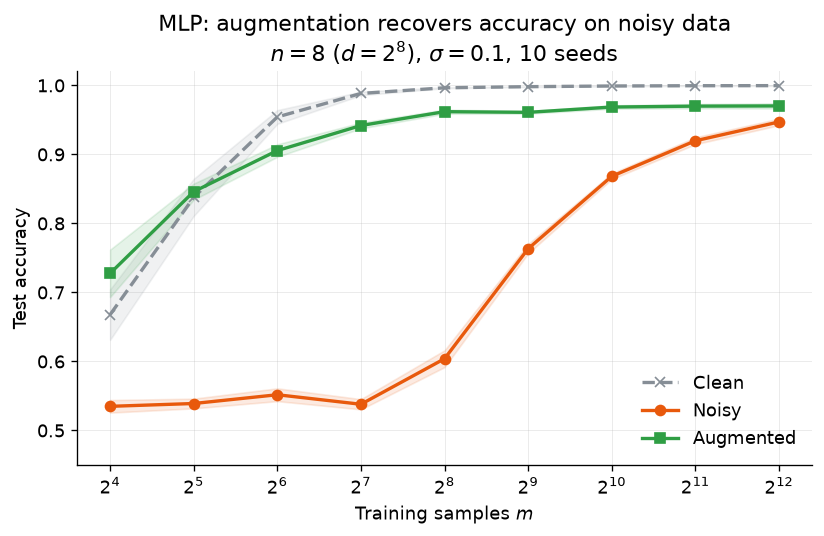

In [13]:
def plot_acc_vs_m(res, n, arch, sigma):
    fig, ax = plt.subplots(figsize=(7, 4.6))
    for cond in CONDS:
        x, mu, sd = ms(res[cond][n])
        st = COND_STYLE[cond]
        ax.plot(x, mu, marker=st["marker"], ls=st["ls"], color=st["color"],
                label=st["label"], lw=2, ms=6)
        ax.fill_between(x, mu - sd, mu + sd, color=st["color"], alpha=0.12)
    ax.set_xscale("log", base=2)
    ax.set_xlabel("Training samples $m$")
    ax.set_ylabel("Test accuracy")
    ax.set_ylim(0.45, 1.02)
    ax.set_title(f"{arch}: augmentation recovers accuracy on noisy data\n"
                 fr"$n={n}$ ($d=2^{{{n}}}$), $\sigma={sigma}$, {nreps(res['clean'][n])} seeds")
    ax.legend(loc="lower right")
    fig.tight_layout()
    save(fig, "01_acc_vs_m_best")


plot_acc_vs_m(res_m[BEST], 8, BEST, 0.1)
plt.show()

### 2 — Architecture comparison
Augmented accuracy and augmentation gain for all four models. Even the 245-parameter
CNN benefits; the MLP shows the largest recovery.

In [14]:
d = 2 ** 8  # n = 8
PARAMS = {
    "MLP": count_params(ARCHS["MLP"]["build"](d)),
    "CNN": count_params(ARCHS["CNN"]["build"](d)),
    # "LSTM": count_params(ARCHS["LSTM"]["build"](d)),
    # "SVM": "—",
}
PARAMS

{'MLP': 4113, 'CNN': 245}

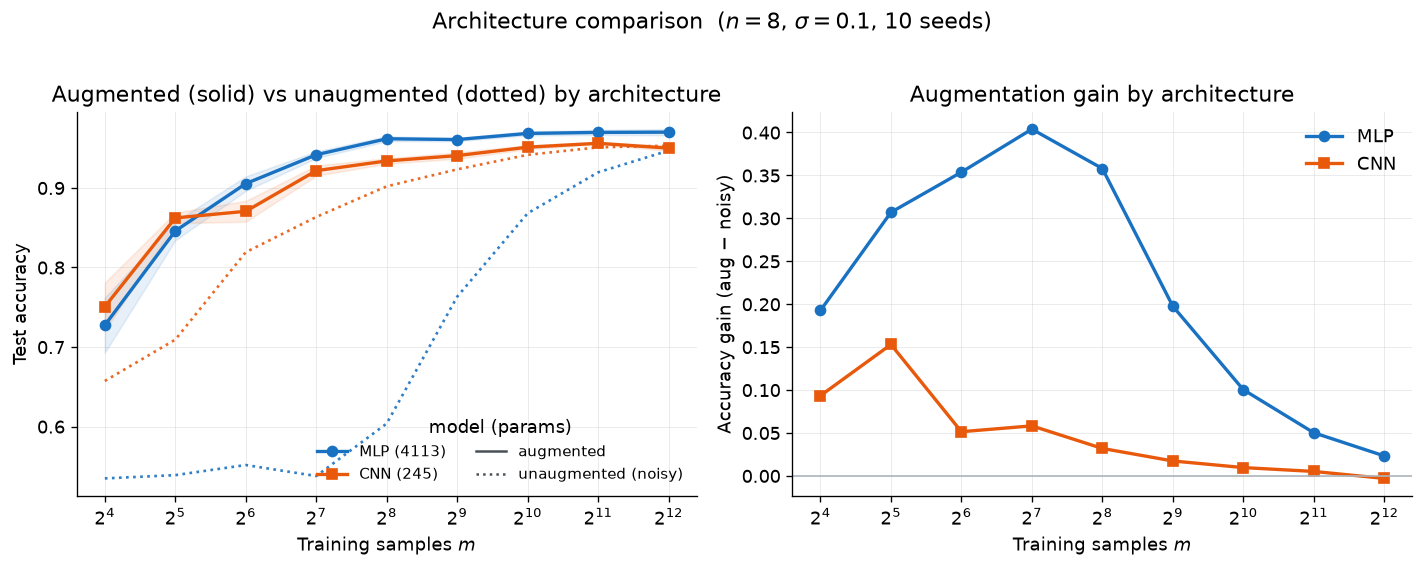

In [15]:
def plot_arch_comparison(res_by_arch, n, sigma, params):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for arch, res in res_by_arch.items():
        x, mu, sd = ms(res["augmented"][n])
        xn, mn, _ = ms(res["noisy"][n])
        axes[0].plot(x, mu, marker=ARCH_MARKER[arch], color=ARCH_COLOR[arch],
                     lw=2, ms=6, label=f"{arch} ({params[arch]})")
        axes[0].fill_between(x, mu - sd, mu + sd, color=ARCH_COLOR[arch], alpha=0.10)
        axes[0].plot(xn, mn, ls=":", lw=1.6, color=ARCH_COLOR[arch], alpha=0.9)
        axes[1].plot(x, mu - mn, marker=ARCH_MARKER[arch], color=ARCH_COLOR[arch],
                     lw=2, ms=6, label=arch)
    for a in axes:
        a.set_xscale("log", base=2)
        a.set_xlabel("Training samples $m$")
    axes[0].plot([], [], ls="-", color="#495057", label="augmented")
    axes[0].plot([], [], ls=":", color="#495057", label="unaugmented (noisy)")
    axes[0].set_ylabel("Test accuracy")
    axes[0].set_title("Augmented (solid) vs unaugmented (dotted) by architecture")
    axes[0].legend(title="model (params)", loc="lower right", ncol=2, fontsize=9)
    axes[1].axhline(0, color="#adb5bd", lw=1)
    axes[1].set_ylabel("Accuracy gain (aug $-$ noisy)")
    axes[1].set_title("Augmentation gain by architecture")
    axes[1].legend(loc="upper right")
    reps = nreps(res_by_arch[list(res_by_arch)[0]]["augmented"][n])
    fig.suptitle(fr"Architecture comparison  ($n={n}$, $\sigma={sigma}$, {reps} seeds)", y=1.02)
    fig.tight_layout()
    save(fig, "02_arch_comparison")


plot_arch_comparison(res_m, 8, 0.1, PARAMS)
plt.show()

### 3 — Where the improvement comes from
Recovery over the noisy baseline (left) and the remaining gap to the clean ceiling
(right), with system size as a colour gradient.

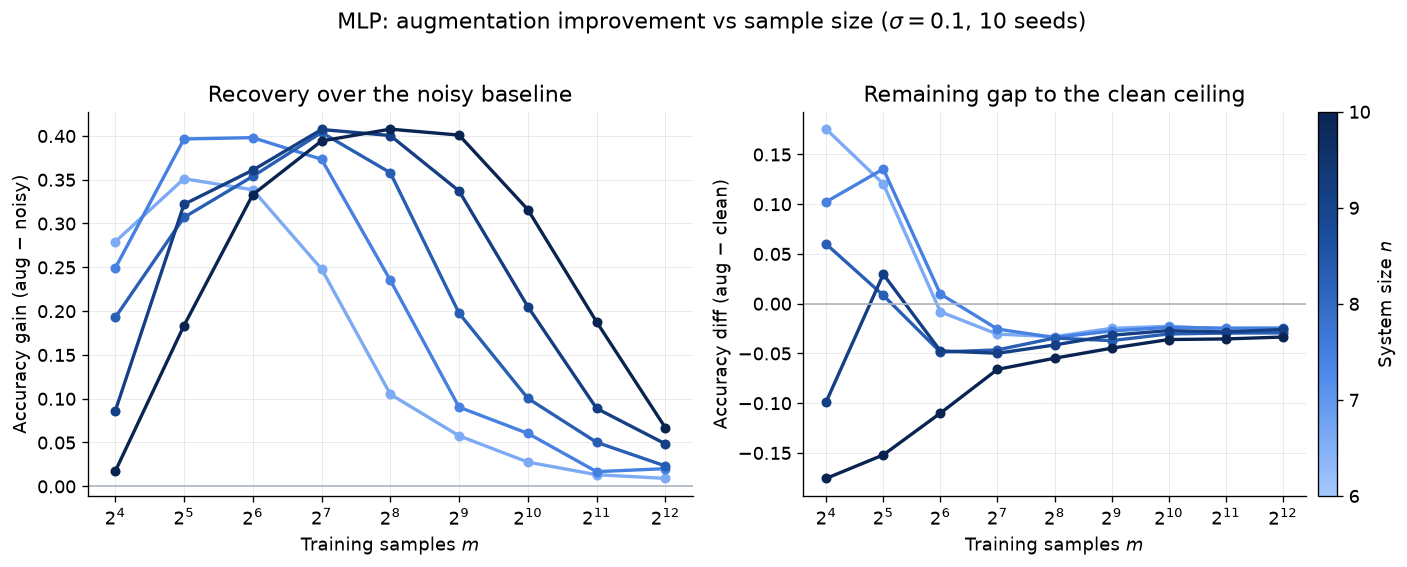

In [16]:
def plot_improvement(res, n_values, arch, sigma):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for n in n_values:
        c = ncolor(n, n_values)
        x, ma, _ = ms(res["augmented"][n])
        _, mn, _ = ms(res["noisy"][n])
        _, mc, _ = ms(res["clean"][n])
        axes[0].plot(x, ma - mn, marker="o", color=c, lw=2, ms=5)
        axes[1].plot(x, ma - mc, marker="o", color=c, lw=2, ms=5)
    for a, ttl, yl in zip(
            axes, ["Recovery over the noisy baseline", "Remaining gap to the clean ceiling"],
            ["Accuracy gain (aug $-$ noisy)", "Accuracy diff (aug $-$ clean)"]):
        a.axhline(0, color="#adb5bd", lw=1)
        a.set_xscale("log", base=2)
        a.set_xlabel("Training samples $m$")
        a.set_ylabel(yl)
        a.set_title(ttl)
    add_n_colorbar(fig, axes[1], n_values)
    fig.suptitle(fr"{arch}: augmentation improvement vs sample size "
                 fr"($\sigma={sigma}$, {nreps(res['augmented'])} seeds)", y=1.02)
    fig.tight_layout()
    save(fig, "03_improvement")


plot_improvement(res_m[BEST], N_VALUES, BEST, 0.1)
plt.show()

### 4 — Gain vs system size
The paper reports that its PCA/MSE benefit *grows* with $n$. For a bounded metric like
accuracy that does not carry over: at fixed $m$ the gain is roughly flat and if anything
declines with $n$, because a fixed sample count covers an exponentially larger space ever
more sparsely, so the noisy baseline collapses faster than augmentation can compensate.

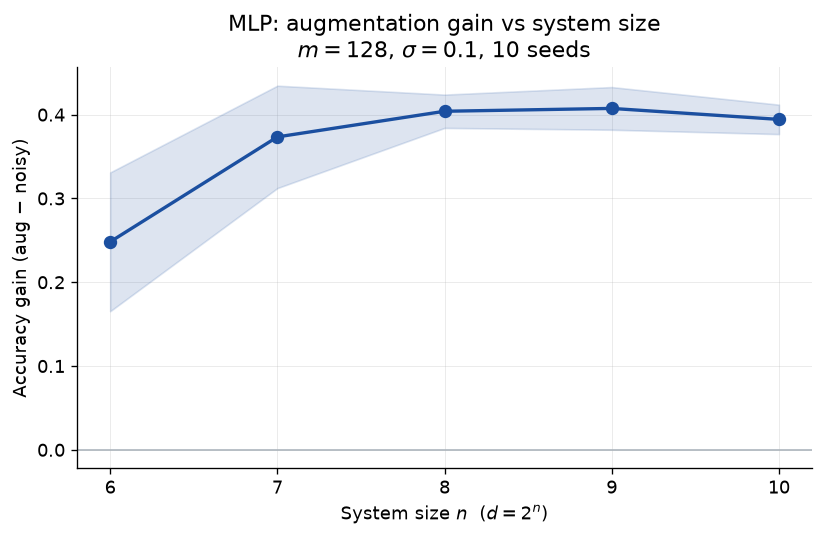

In [17]:
def plot_gain_vs_n(res, n_values, arch, sigma, m):
    fig, ax = plt.subplots(figsize=(7, 4.6))
    g = np.array([(res["augmented"][n][m] - res["noisy"][n][m]).mean() for n in n_values])
    s = np.array([(res["augmented"][n][m] - res["noisy"][n][m]).std() for n in n_values])
    ax.plot(n_values, g, marker="o", color="#1b4fa0", lw=2, ms=7)
    ax.fill_between(n_values, g - s, g + s, color="#1b4fa0", alpha=0.15)
    ax.axhline(0, color="#adb5bd", lw=1)
    ax.set_xlabel("System size $n$  ($d=2^{n}$)")
    ax.set_ylabel("Accuracy gain (aug $-$ noisy)")
    ax.set_xticks(list(n_values))
    ax.set_title(f"{arch}: augmentation gain vs system size\n"
                 fr"$m={m}$, $\sigma={sigma}$, {nreps(res['augmented'])} seeds")
    fig.tight_layout()
    save(fig, "04_gain_vs_n")


plot_gain_vs_n(res_m[BEST], N_VALUES, BEST, 0.1, 128)
plt.show()

### 5 — Robustness across noise levels
Augmentation gain against $\sigma$ (left, gradient over $n$) and the accuracy of the
noisy vs augmented model at the largest size (right). The benefit peaks in the
moderate-noise regime and vanishes once the signal is fully masked.

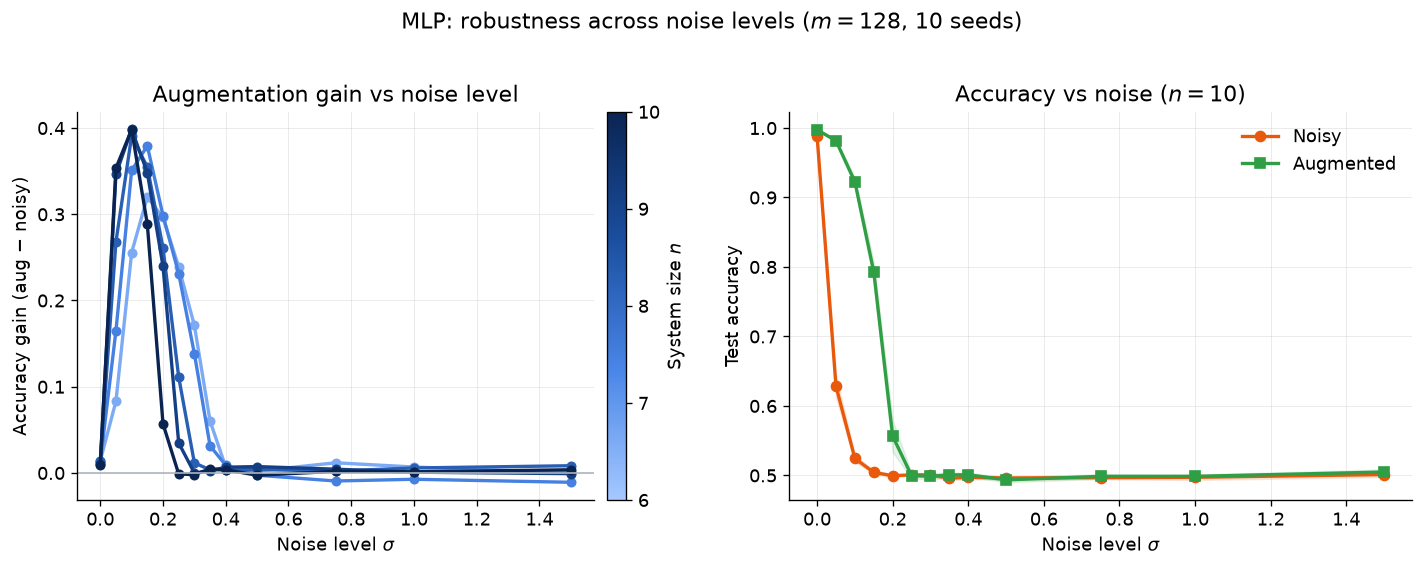

In [18]:
def plot_sigma(res, n_values, arch, m):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for n in n_values:
        x, ma, _ = ms(res["augmented"][n])
        _, mn, _ = ms(res["noisy"][n])
        axes[0].plot(x, ma - mn, marker="o", color=ncolor(n, n_values), lw=2, ms=5)
    nref = max(n_values)
    x, ma, sa = ms(res["augmented"][nref])
    _, mn, sn = ms(res["noisy"][nref])
    axes[1].plot(x, mn, marker="o", color=COND_STYLE["noisy"]["color"], lw=2, label="Noisy")
    axes[1].fill_between(x, mn - sn, mn + sn, color=COND_STYLE["noisy"]["color"], alpha=0.12)
    axes[1].plot(x, ma, marker="s", color=COND_STYLE["augmented"]["color"], lw=2, label="Augmented")
    axes[1].fill_between(x, ma - sa, ma + sa, color=COND_STYLE["augmented"]["color"], alpha=0.12)
    axes[0].axhline(0, color="#adb5bd", lw=1)
    axes[0].set_xlabel(r"Noise level $\sigma$")
    axes[0].set_ylabel("Accuracy gain (aug $-$ noisy)")
    axes[0].set_title("Augmentation gain vs noise level")
    add_n_colorbar(fig, axes[0], n_values)
    axes[1].set_xlabel(r"Noise level $\sigma$")
    axes[1].set_ylabel("Test accuracy")
    axes[1].set_title(fr"Accuracy vs noise ($n={nref}$)")
    axes[1].legend(loc="upper right")
    fig.suptitle(fr"{arch}: robustness across noise levels "
                 fr"($m={m}$, {nreps(res['augmented'])} seeds)", y=1.02)
    fig.tight_layout()
    save(fig, "05_sigma_sweep")


plot_sigma(res_sigma, N_VALUES, BEST, 128)
plt.show()

### 6 — Effect of the augmentation window size
Gain as a function of $|\Omega|$. A window of size one is the identity (no
augmentation); enlarging it helps up to a point that grows with $n$.

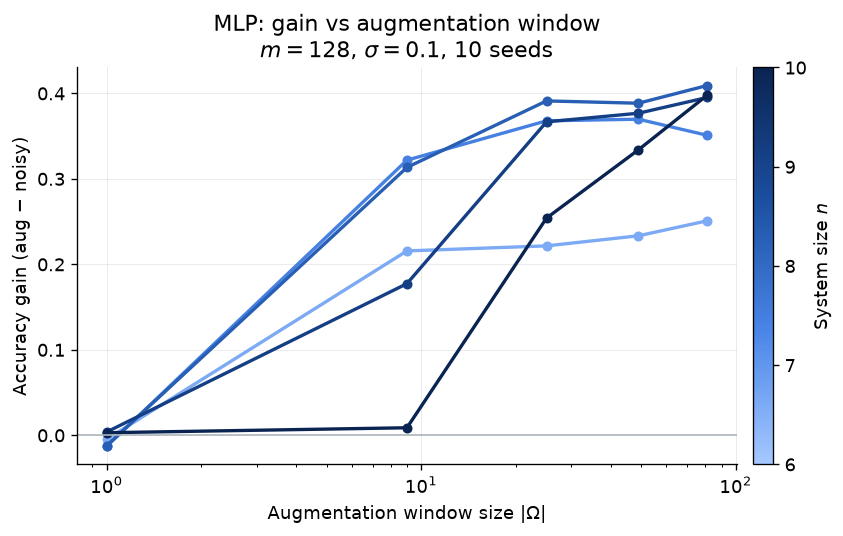

In [19]:
def plot_omega(res, n_values, arch, m, sigma):
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    for n in n_values:
        x, ma, _ = ms(res["augmented"][n])
        _, mn, _ = ms(res["noisy"][n])
        ax.plot(x, ma - mn, marker="o", color=ncolor(n, n_values), lw=2, ms=5)
    ax.axhline(0, color="#adb5bd", lw=1)
    ax.set_xscale("log")
    ax.set_xlabel(r"Augmentation window size $|\Omega|$")
    ax.set_ylabel("Accuracy gain (aug $-$ noisy)")
    ax.set_title(f"{arch}: gain vs augmentation window\n"
                 fr"$m={m}$, $\sigma={sigma}$, {nreps(res['augmented'])} seeds")
    add_n_colorbar(fig, ax, n_values)
    fig.tight_layout()
    save(fig, "06_omega_sweep")


plot_omega(res_omega, N_VALUES, BEST, 128, 0.1)
plt.show()

### 7 — Parameter efficiency
Augmented accuracy at $n=8$, $m=256$ against model size. The CNN reaches competitive
accuracy with two orders of magnitude fewer parameters than the MLP.

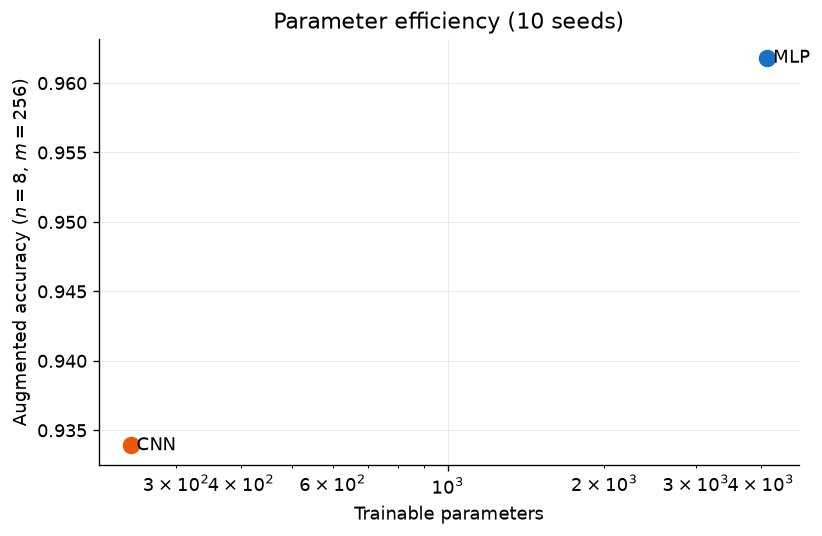

In [20]:
def plot_param_efficiency(res_by_arch, n, m):
    fig, ax = plt.subplots(figsize=(7, 4.6))
    for arch, res in res_by_arch.items():
        p = PARAMS[arch]
        if p == "—":
            continue
        acc = res["augmented"][n][m].mean()
        ax.scatter(p, acc, s=90, color=ARCH_COLOR[arch], zorder=3)
        ax.annotate(f" {arch}", (p, acc), va="center")
    ax.set_xscale("log")
    ax.set_xlabel("Trainable parameters")
    ax.set_ylabel(fr"Augmented accuracy ($n={n}$, $m={m}$)")
    reps = nreps(res_by_arch[list(res_by_arch)[0]]["augmented"][n])
    ax.set_title(f"Parameter efficiency ({reps} seeds)")
    fig.tight_layout()
    save(fig, "07_param_efficiency")


plot_param_efficiency(res_m, 8, 256)
plt.show()

### 9 — How much of the gap is recovered
The normalized recovery $(\mathrm{aug}-\mathrm{noisy})/(\mathrm{clean}-\mathrm{noisy})$:
the fraction of the accuracy lost to noise that augmentation wins back. It is comparable
across $n$ and directly answers how much augmentation actually helps.

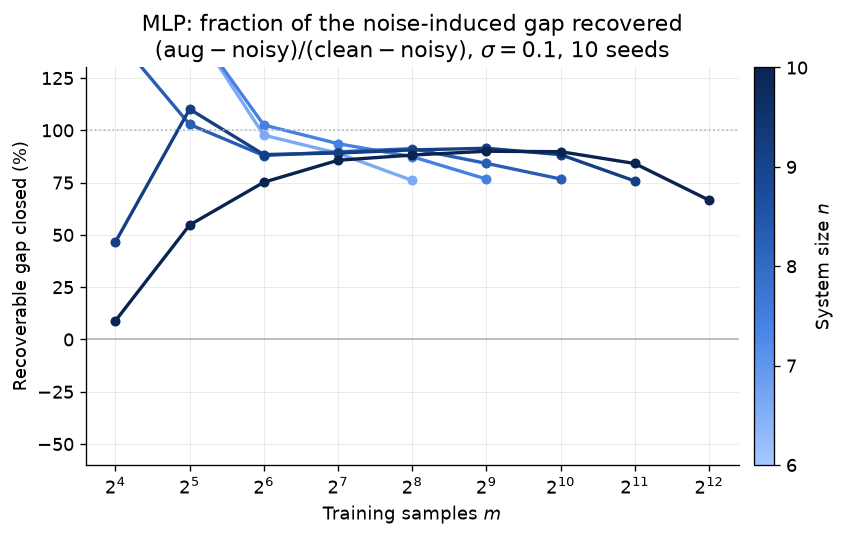

In [21]:
def plot_gap_closed(res, n_values, arch, sigma, min_gap=0.1):
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    for n in n_values:
        xs = sorted(res["clean"][n])
        mm, frac = [], []
        for m in xs:
            c = res["clean"][n][m].mean()
            z = res["noisy"][n][m].mean()
            a = res["augmented"][n][m].mean()
            if c - z > min_gap:
                mm.append(m)
                frac.append(100 * (a - z) / (c - z))
        ax.plot(mm, frac, marker="o", color=ncolor(n, n_values), lw=2, ms=5)
    ax.axhline(0, color="#adb5bd", lw=1)
    ax.axhline(100, color="#adb5bd", lw=1, ls=":")
    ax.set_ylim(-60, 130)
    ax.set_xscale("log", base=2)
    ax.set_xlabel("Training samples $m$")
    ax.set_ylabel("Recoverable gap closed (%)")
    ax.set_title(f"{arch}: fraction of the noise-induced gap recovered\n"
                 fr"$(\mathrm{{aug}}-\mathrm{{noisy}})/(\mathrm{{clean}}-\mathrm{{noisy}})$, "
                 fr"$\sigma={sigma}$, {nreps(res['augmented'])} seeds")
    add_n_colorbar(fig, ax, n_values)
    fig.tight_layout()
    save(fig, "09_gap_closed")


plot_gap_closed(res_m[BEST], N_VALUES, BEST, 0.1)
plt.show()

### 11 — Noise × window interdependence
A 2D sweep at fixed $n$, $m$: for each noise level we compute the noisy baseline once, then
the augmentation gain for a range of window sizes. This shows whether a larger window
extends the advantage to higher noise (the noisy baseline is recomputed per $\sigma$ only).

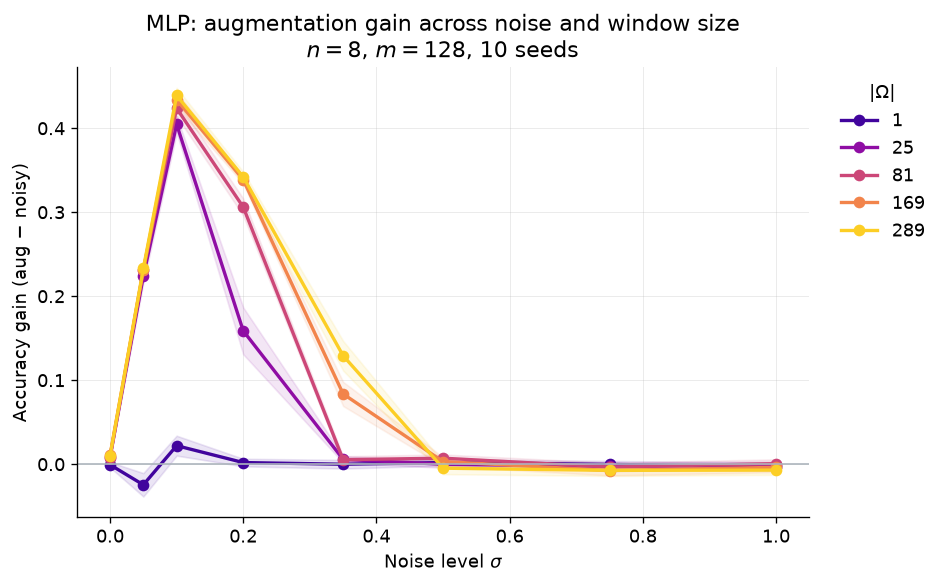

In [22]:
def sweep_sigma_omega(arch, n, sigma_values, sizes, m, seeds, force=False):
    key = dict(kind="sig_omega", arch=arch, n=n, sigma=list(sigma_values),
               sizes=list(sizes), m=m, seeds=list(seeds))

    def run():
        X0, _, X1, _ = load_dataset(n)
        d = X0.shape[1]
        pool0, pool1, (Xva, yva), (Xte, yte) = make_pools(X0, X1)
        out = {"noisy": {}, "augmented": {}}
        t0, done = time.time(), 0
        for sig in sigma_values:
            noisy, aug = [], {s: [] for s in sizes}
            for seed in seeds:
                Xtr, ytr = draw_train(pool0, pool1, m, seed)
                trng, erng = np.random.default_rng(1000 + seed), np.random.default_rng(999)
                Xtr_n = add_noise(Xtr, sig, trng)
                Xva_n, Xte_n = add_noise(Xva, sig, erng), add_noise(Xte, sig, erng)
                noisy.append(fit_eval(arch, d, Xtr_n, ytr, None, Xva_n, yva, Xte_n, yte, seed))
                for s in sizes:
                    Xa, ya, wa = make_augmented(Xtr_n, ytr, s)
                    aug[s].append(fit_eval(arch, d, Xa, ya, wa, Xva_n, yva, Xte_n, yte, seed))
            out["noisy"][sig] = np.array(noisy)
            out["augmented"][sig] = {s ** 2: np.array(aug[s]) for s in sizes}
            done += 1
            _log(f"sweep_sig_omega {arch}", done, len(sigma_values), t0, f"sigma={sig}")
        return out
    return cached(key, run, force)


def plot_sigma_omega(res, sigma_values, n, m, arch):
    omegas = sorted(res["augmented"][sigma_values[0]].keys())
    cmap = plt.cm.plasma
    fig, ax = plt.subplots(figsize=(8, 5))
    for i, o in enumerate(omegas):
        g = [res["augmented"][s][o].mean() - res["noisy"][s].mean() for s in sigma_values]
        sd = [np.sqrt(res["augmented"][s][o].std() ** 2 + res["noisy"][s].std() ** 2)
              / np.sqrt(len(res["noisy"][s])) for s in sigma_values]
        c = cmap(0.1 + 0.8 * i / max(1, len(omegas) - 1))
        ax.plot(sigma_values, g, marker="o", color=c, lw=2, label=f"{o}")
        ax.fill_between(sigma_values, np.array(g) - sd, np.array(g) + sd, color=c, alpha=0.1)
    ax.axhline(0, color="#adb5bd", lw=1)
    ax.set_xlabel(r"Noise level $\sigma$")
    ax.set_ylabel("Accuracy gain (aug $-$ noisy)")
    ax.set_title(f"{arch}: augmentation gain across noise and window size\n"
                 fr"$n={n}$, $m={m}$, {len(res['noisy'][sigma_values[0]])} seeds")
    ax.legend(title=r"$|\Omega|$", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    save(fig, "11_sigma_omega")


res_so = sweep_sigma_omega("MLP", 8, [0.0, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0],
                           [1, 5, 9, 13, 17], 128, SEEDS)
plot_sigma_omega(res_so, [0.0, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0], 8, 128, "MLP")
plt.show()

### 12 — Adaptive window (separate experiment)
A standalone check, kept apart from the main results: for each $(n, \sigma)$ the augmentation
window is **selected by validation accuracy** from a candidate set, so it adapts to the noise
level. Compared to the fixed $n$-dependent window of section 5, this lets the advantage
survive to higher $\sigma$. Left: gain vs $\sigma$ (gradient over $n$). Right: the window the
validation picks, which grows with the noise.

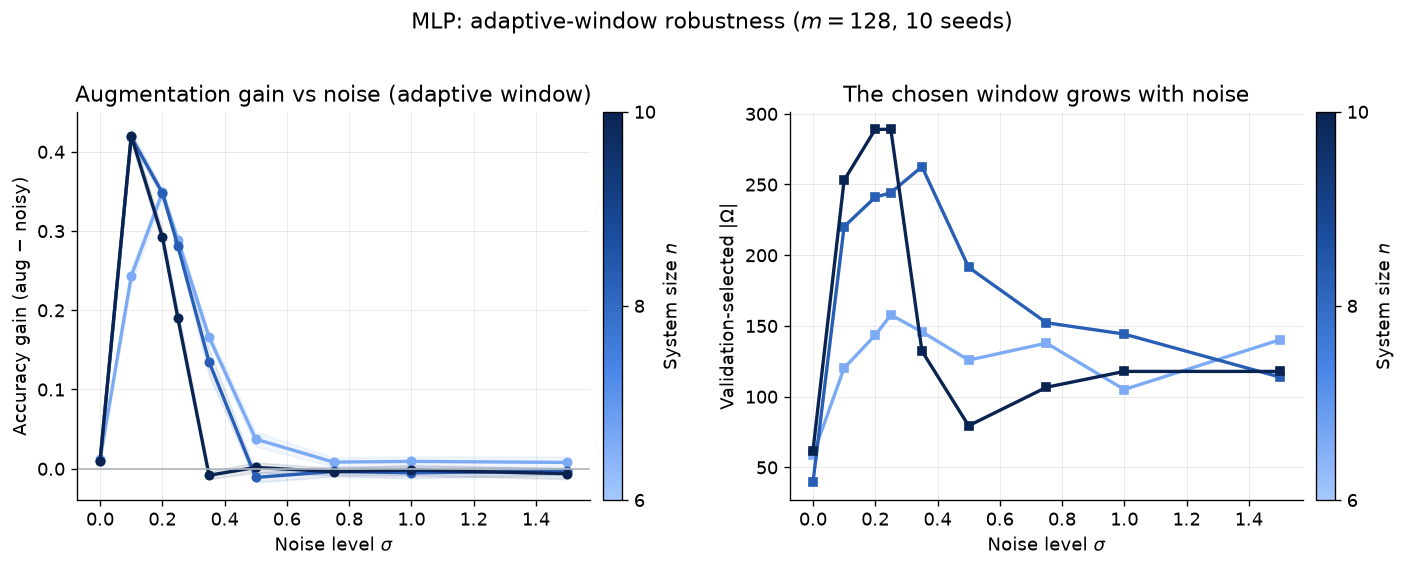

In [23]:
def plot_sigma_adaptive(res, n_values, arch, m):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for n in n_values:
        c = ncolor(n, n_values)
        x, ma, sa = ms(res["augmented"][n])
        _, mn, mnsem = ms(res["noisy"][n])
        gain = ma - mn
        gsem = np.sqrt(sa ** 2 + mnsem ** 2)
        axes[0].plot(x, gain, marker="o", color=c, lw=2, ms=5)
        axes[0].fill_between(x, gain - gsem, gain + gsem, color=c, alpha=0.1)
        xc, mc, _ = ms(res["chosen"][n])
        axes[1].plot(xc, mc, marker="s", color=c, lw=2, ms=5)
    axes[0].axhline(0, color="#adb5bd", lw=1)
    axes[0].set_xlabel(r"Noise level $\sigma$")
    axes[0].set_ylabel("Accuracy gain (aug $-$ noisy)")
    axes[0].set_title("Augmentation gain vs noise (adaptive window)")
    add_n_colorbar(fig, axes[0], n_values)
    axes[1].set_xlabel(r"Noise level $\sigma$")
    axes[1].set_ylabel(r"Validation-selected $|\Omega|$")
    axes[1].set_title("The chosen window grows with noise")
    add_n_colorbar(fig, axes[1], n_values)
    fig.suptitle(fr"{arch}: adaptive-window robustness "
                 fr"($m={m}$, {nreps(res['augmented'])} seeds)", y=1.02)
    fig.tight_layout()
    save(fig, "12_sigma_adaptive")


N_ADAPT = [6, 8, 10]
SIGMA_ADAPT = [0.0, 0.1, 0.2, 0.25, 0.35, 0.5, 0.75, 1.0, 1.5]
CAND_ADAPT = [5, 9, 13, 17]
res_sigma_adaptive = sweep_sigma_adaptive(BEST, N_ADAPT, SIGMA_ADAPT, CAND_ADAPT, 128, SEEDS)
plot_sigma_adaptive(res_sigma_adaptive, N_ADAPT, BEST, 128)
plt.show()

## Summary

For both the MLP and the tiny CNN, Weyl–Heisenberg augmentation recovers a substantial
fraction of the accuracy that additive noise removes, and it helps even for a model with a
few hundred parameters. The benefit is largest in the small-sample, moderate-noise regime
and fades once the signal is fully masked. The augmentation window matters: with the
paper's $n$-dependent window (and, as the $\sigma\times|\Omega|$ sweep shows, a larger
window at higher noise) the advantage extends well beyond a single noise level. These
establish the classical baseline that motivates the quantum analogues studied next.